##Sentiment Analyzer

**SentimentIntensityAnalyzer** is a sentiment analysis tool from Python's NLTK (Natural Language Toolkit) library. It uses **VADER** (Valence Aware Dictionary and sEntiment Reasoner) to determine whether a piece of text expresses a positive, negative, or neutral sentiment.

It is commonly used in Natural Language Processing (NLP) to analyze customer reviews, social media posts, product feedback, and other short texts.

**How does SentimentIntensityAnalyzer work?**
Unlike machine learning models that require training data, SentimentIntensityAnalyzer uses a lexicon-based and rule-based approach.
It evaluates words based on predefined sentiment scores and considers contextual factors such as capitalization, punctuation, intensifiers, and negation.
For example:
- "I love this product!" → Positive
- "This product is terrible." → Negative
- "The product arrived yesterday." → Neutral
- "This product is VERY GOOD!!!" → Strongly positive



In [ ]:
# STEP 1. Import baseline libraries

import nltk
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tokenize import word_tokenize
nltk.download("vader_lexicon", quiet = True)
nltk.download('punkt_tab', quiet = True)
import pandas as pd
import numpy as np

nltk.download('punkt_tab', quiet = True)
nltk.download('stopwords', quiet = True)
nltk.download('wordnet', quiet = True)

In [ ]:
#Practice code
sia = SentimentIntensityAnalyzer()

text = 'I don\'t like your attitude'

scores = sia.polarity_scores(text)

print(scores)

**Understanding the sentiment scores**

**Score	Description**
- neg ( <= -0.05)	- Proportion of text associated with negative sentiment
- neu (-0.05 to +0.05)  - Proportion of text associated with neutral sentiment
- pos (>= +0.05) - Proportion of text associated with positive sentiment
- compound - 	Overall normalized sentiment score ranging from -1 to +1

**The compound score is commonly used to classify sentiment.**

In [ ]:
#Sample Customer Review

reviews = [
    'The product is excellent!',
    'I hate this product',
    'The package arrived yesterday.',
    'The service was not good.',
    'I absolutely LOVE this phone!!!'
]

for review in reviews:

  scores = sia.polarity_scores(review)
  compound = scores['compound']

  if compound >= 0.05:
    sentiment = 'Positive'
  elif compound <= -0.05:
    sentiment = 'Negative'
  else:
    sentiment = 'Neutral'

  print('Review: ', review)
  print('Compound Score: ', compound)
  print('Sentiment: ', sentiment)

**SentimentIntensityAnalyzer vs. TF-IDF**

These two NLP techniques serve different purposes.

- **Purpose**: SentimentIntensityAnalyzer detect sentiment	while  TF-IDF represent text numerically
- **Approach**: SIA uses Lexicon and rules	while TF-IDF uses statistical word weighting
- **Requires training?**	SIA - No, TF-IDF - No, but fits a vocabulary and IDF weights
- **Output**	SIA - Sentiment scores, TF-IDF - Numerical feature vectors
- **Typical application**	SIA - Customer feedback analysis, TF-IDF - Text classification with ML

**Advantages and limitations**

- **Advantages:** Easy to implement, does not require labeled training data, works well with short informal English text, and recognizes some emphasis through punctuation and capitalization.

- **Limitations**: It may struggle with sarcasm, complex sentence structures, domain-specific terminology, and Filipino or Taglish expressions without customization.

**Sentiment Analysis Using TF-IDF and Machine Learning Classifiers**

This example demonstrates how to build a sentiment analysis model using TF-IDF and machine learning in Python. Unlike SentimentIntensityAnalyzer, which uses predefined sentiment rules, this approach learns patterns from labeled training data.

We will use three classifiers:
1. Multinomial Naive Bayes
2. Logistic Regression
3. Support Vector Machine (SVM)

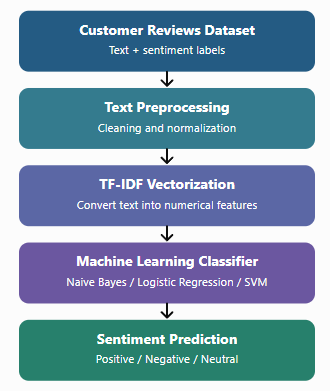


In [ ]:
#STEP1. Import core and helping libraries

import pandas as pd
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
#STEP 2. Load sample dataset

data = {
    "review": [
        # Positive reviews
        "This product is excellent and works perfectly",
        "I love this amazing product",
        "The service was wonderful and fast",
        "Very satisfied with my purchase",
        "Great quality and excellent performance",
        "The product exceeded my expectations",
        "I am extremely happy with this item even though it's pricey.",
        "Fantastic experience and friendly staff",
        "The delivery was quick and reliable",
        "Highly recommended and worth buying",

        # Negative reviews
        "This product is terrible and useless",
        "I hate the poor quality",
        "The service was awful and slow",
        "Very disappointed with my purchase",
        "Bad quality and horrible performance",
        "The product failed after one day",
        "I am unhappy with this item",
        "Terrible experience and rude staff",
        "The delivery was delayed and unreliable",
        "Not recommended and a waste of money",

        # Neutral reviews
        "The product arrived yesterday, but it was damaged!",
        "The package contains two items",
        "The product is available in black",
        "I purchased this item last week",
        "The delivery took three days",
        "The product comes with a manual",
        "The item weighs one kilogram",
        "The store opens at nine",
        "The product has a one year warranty",
        "The package was delivered this morning"

        #Additional Reviews
    ],

    "sentiment": (
        ["Positive"] * 10 +
        ["Negative"] * 10 +
        ["Neutral"] * 10
    )
}

import pandas as pd

# Transform the 'data' dictionary into a pandas DataFrame
df_transformed = pd.DataFrame(data)

# Display the DataFrame
display(df_transformed)

print(df_transformed["sentiment"].value_counts())

In [ ]:
#Step 3. Apply text preprocessing
#We will convert text to lowercase, remove URLs, and remove unnecessary special characters.

def preprocess_text(text):
  text = text.lower()
  text = re.sub(r'http\S+|wwwS+', '', text)
  text = re.sub(r'[^a-z\s]', '', text)
  text = re.sub(r'\s+', ' ', text).strip()
  return text

df_transformed['clean_review'] = df_transformed['review'].apply(preprocess_text)

print(df_transformed[['review', 'clean_review']].head())

In [ ]:
#Step 4. Split the dataset into training and testing sets
X = df_transformed['clean_review']
y = df_transformed['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.30,
    random_state = 42,
    stratify = y
)

print('Training Samples: ', len(X_train))
print('Testing Samples: ', len(X_test))

In [ ]:
#Step 5. Apply TF-IDF vectorization
#TF-IDF converts text into numerical vectors based on how important words are across documents.

tfidf = TfidfVectorizer(
    max_features = 1000,
    ngram_range = (1, 2),
    stop_words = None
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print('TF-IDF matrix shape: ', X_train_tfidf.shape)

print('Features:')
print(tfidf.get_feature_names_out())

# Convert the sparse TF-IDF matrix into a dense DataFrame to print it as a table
tfidf_df = pd.DataFrame(
    X_train_tfidf.toarray(),
    columns = tfidf.get_feature_names_out()
)

# Display the TF-IDF matrix table (first 5 rows and first 10 features for readability)
display(tfidf_df.iloc[:5, :10])

**Understanding parameters:**

**Parameter	Function**
1. **max_features=1000**	Limits the vocabulary to at most 1,000 features
2. **ngram_range=(1,2)**	Extracts individual words and two-word combinations
3. **stop_words**=None	Retains stop words, including negations
4. **fit_transform()**	Learns vocabulary and IDF values, then transforms training text
5. **transform()**	Converts test data using the vocabulary learned from training data

##Train three machine learning classifiers

In [ ]:
#Classifier 1: Multinomial Naive Bayes
#Naive Bayes is a probabilistic classifier commonly used for text classification.

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print('Naive Bayes Accuracy:',
      accuracy_score(y_test, nb_predictions))

print(classification_report(
    y_test,
    nb_predictions,
    zero_division = 0))

In [ ]:
#Classifier 2: Logistic Regression
#Logistic Regression learns weights for TF-IDF features to predict the probability of each sentiment category.

lr_model = LogisticRegression(
    max_iter = 1000,
    random_state = 42
)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

print('Logistic Regression Accuracy:',
      accuracy_score(y_test, lr_predictions))

print(classification_report(
    y_test,
    lr_predictions,
    zero_division = 0))

In [ ]:
#Classifier 3: Support Vector Machine (SVM)
#Linear SVM finds decision boundaries between sentiment classes.
#It is often effective with high-dimensional TF-IDF features.

svm_model = LinearSVC(
    random_state = 42
)

svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

print('Linear SVM Accuracy:',
      accuracy_score(y_test, svm_predictions))

print(classification_report(
    y_test,
    svm_predictions,
    zero_division = 0))

In [ ]:
#Compare classifier performance


In [ ]:
#Predict sentiment for new customer reviews

new_reviews = [
    "I really love the quality of this product",
    "The service was horrible and disappointing",
    "The package arrived this afternoon",
    "The item is not good",
]

clean_reviews = [
    preprocess_text(review)
    for review in new_reviews
]

new_tfidf = tfidf.transform(clean_reviews)

predictions = svm_model.predict(new_tfidf)

for review, sentiment in zip(new_reviews, predictions):
  print('Review: ', review)
  print('Predicted Sentiment: ', sentiment)
  print()

###ANOTHER EXAMPLE USING SENTIMENT ANALYZER

In [ ]:

#STEP 1. Load the dataset

import pandas as pd
from google.colab import files

upload = files.upload()

df_new = pd.read_excel('customer_reviews.xlsx')
print(df_new.shape)
print(df_new['sentiment'].values[:10])

In [ ]:
#STEP 2.  Define function for preprocessing text data
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet', quiet = True)

stop_words = set(stopwords.words())
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # convert to lowercase
    text = str(text).lower()

    # Tokenize text
    tokens = word_tokenize(text)

    # Remove stopwords and non-alphabetic characters
    filtered_tokens = [token for token in tokens if token.isalnum() and token not in stop_words]

    # Lemmatize tokens
    lemmatized_tokens = [lemmatizer.lemmatize(token) for token in filtered_tokens]

    # Join tokens back into a string
    clean_text = ' '.join(lemmatized_tokens)

    return clean_text

# Apply preprocessing function to the correct text data column ('review')
df_new['clean_review'] = df_new['review'].apply(preprocess_text)

print(df_new[['review', 'clean_review']].head())

In [ ]:
# STEP 3.  Define function for sentiment analysis

#initialize sentiment analyzer

sia = SentimentIntensityAnalyzer()

#function for sentiment analyis

def sia_analysis(text):
  scores = sia.polarity_scores(text)

  return scores

# Apply sentiment analysis function to text data
df_new['sia_scores'] = df_new['clean_review'].apply(sia_analysis)

print(df_new[['clean_review', 'sia_scores', 'sentiment']].head())

In [ ]:
# STEP 5. Define text data

for review in df_new['clean_review']:

  # Calculate sentiment scores
  scores = sia.polarity_scores(review)
  compound = scores['compound']

  # Determine sentiment label
  if compound >= 0.05:
    sentiment = 'Positive'
  elif compound <= -0.05:
    sentiment = 'Negative'
  else:
    sentiment = 'Neutral'

  print('Review: ', review)
  print('Compound Score: ', compound)
  print('Sentiment: ', sentiment)
  print()

##CHALLENGE 1. USING THE DATASESET CUSTOMER_REVIEW APPLY TF-IDF AND MACHINE LEARNING TO CLASSIFY SENTIMENT
Evaluate the model with new data:

- Ask the user to input a message and classify whether positive, neutral or negative sentiment. Display the sentiment score.
- Count all positive, neutral and negative sentiments and display as a dataframe.
- Create a visualization of your results.
- Compare performance of the 3 machine learning model.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_fscore_support

X_cr = df_new['clean_review']
y_cr = df_new['sentiment'].astype(str).str.strip().str.title()

X_train_cr, X_test_cr, y_train_cr, y_test_cr = train_test_split(
    X_cr, y_cr, test_size = 0.30, random_state = 42, stratify = y_cr
)

tfidf_cr = TfidfVectorizer(max_features = 1000, ngram_range = (1, 2), stop_words = None)
X_train_cr_tfidf = tfidf_cr.fit_transform(X_train_cr)
X_test_cr_tfidf = tfidf_cr.transform(X_test_cr)

print('Training Samples:', X_train_cr_tfidf.shape[0])
print('Testing Samples :', X_test_cr_tfidf.shape[0])
print('TF-IDF matrix shape:', X_train_cr_tfidf.shape)

In [ ]:
models_cr = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter = 1000, random_state = 42),
    'Linear SVM': LinearSVC(random_state = 42)
}

results = []
predictions_cr = {}

for name, model in models_cr.items():
    model.fit(X_train_cr_tfidf, y_train_cr)
    pred = model.predict(X_test_cr_tfidf)
    predictions_cr[name] = pred

    prec, rec, f1, _ = precision_recall_fscore_support(
        y_test_cr, pred, average = 'weighted', zero_division = 0
    )
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_cr, pred),
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

    print(f'===== {name} =====')
    print(classification_report(y_test_cr, pred, zero_division = 0))

comparison_df = (
    pd.DataFrame(results)
    .sort_values('F1-Score', ascending = False)
    .reset_index(drop = True)
    .round(4)
)

print('MODEL PERFORMANCE COMPARISON')
display(comparison_df)

best_name = comparison_df.loc[0, 'Model']
best_model = models_cr[best_name]
print('Best model:', best_name)

In [ ]:
labels_cr = sorted(y_cr.unique())

df_new['ml_sentiment'] = best_model.predict(tfidf_cr.transform(df_new['clean_review']))

counts_df = pd.DataFrame({
    'Actual': y_cr.value_counts(),
    'Predicted (' + best_name + ')': df_new['ml_sentiment'].value_counts()
}).reindex(labels_cr).fillna(0).astype(int)

counts_df.index.name = 'Sentiment'
counts_df.loc['Total'] = counts_df.sum()

print('SENTIMENT COUNTS')
display(counts_df)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize = (20, 5))

# (a) Sentiment counts: actual vs. predicted
counts_df.drop('Total').plot(kind = 'bar', ax = axes[0], edgecolor = 'black')
axes[0].set_title('Sentiment Counts: Actual vs. Predicted')
axes[0].set_ylabel('Number of reviews')
axes[0].tick_params(axis = 'x', rotation = 0)
for container in axes[0].containers:
    axes[0].bar_label(container, padding = 2)

# (b) Model performance comparison
comparison_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-Score']].plot(
    kind = 'bar', ax = axes[1], edgecolor = 'black'
)
axes[1].set_title('Model Performance Comparison')
axes[1].set_ylabel('Score')
axes[1].set_ylim(0, 1.1)
axes[1].tick_params(axis = 'x', rotation = 15)
axes[1].legend(loc = 'lower right')

# (c) Confusion matrix of the best model (test set)
cm = confusion_matrix(y_test_cr, predictions_cr[best_name], labels = labels_cr)
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', cbar = False,
            xticklabels = labels_cr, yticklabels = labels_cr, ax = axes[2])
axes[2].set_title('Confusion Matrix: ' + best_name)
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [ ]:
lr_cr = models_cr['Logistic Regression']   # provides class probabilities

def predict_sentiment(message):
    vec = tfidf_cr.transform([preprocess_text(message)])

    print('=' * 55)
    print('Message:', message)
    print('-' * 55)

    for name, model in models_cr.items():
        print(f'{name:<22}: {model.predict(vec)[0]}')

    # Sentiment scores = Logistic Regression class probabilities
    print('\nSentiment scores (Logistic Regression probabilities):')
    for label, p in zip(lr_cr.classes_, lr_cr.predict_proba(vec)[0]):
        print(f'  {label:<9}: {p:.4f}')

    # VADER compound score for reference
    print(f"\nVADER compound score: {sia.polarity_scores(message)['compound']:+.4f}")
    print(f'Final prediction ({best_name}): {best_model.predict(vec)[0]}')
    print('=' * 55)

print("Type a review to classify it. Type 'quit' to stop.")
while True:
    user_text = input('\nEnter a message: ').strip()
    if user_text.lower() in ('quit', 'exit', 'q', ''):
        print('Done.')
        break
    predict_sentiment(user_text)